# Export source images as PNG
Enter a source number to save its FIRST, NVSS and LoTSS FITS images as PNGs in `Source_PNGs/<source>/`.

In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from astropy.io import fits

ROOT = Path.cwd()  # run the notebook from the project folder
CHANNEL_DIR = ROOT / "Data" / "FITS_BY_CHANNEL"
RADCAT_DIR = ROOT / "Data" / "RADCAT_F"
OUTPUT_DIR = ROOT / "Source_PNGs"
SURVEYS = ("FIRST", "NVSS", "LoTSS")

In [5]:
def find_fits(survey, source_id):
    """First non-empty FITS file for this source (FITS_BY_CHANNEL, then RADCAT_F)."""
    for path in (CHANNEL_DIR / f"{source_id}_{survey}.fits", RADCAT_DIR / survey / f"{source_id}.fits"):
        if path.exists() and path.stat().st_size > 0:
            return path
    return None


def load_image(path):
    with fits.open(path) as hdul:
        data = np.squeeze(np.array(hdul[0].data, dtype=float))
    if data.ndim != 2:
        raise ValueError("no 2D image data")
    return np.nan_to_num(data)


def save_source(source_id, show=True):
    """Save one PNG per survey into Source_PNGs/<source_id>/ and return the saved paths."""
    source_id = str(source_id).strip()
    folder = OUTPUT_DIR / source_id
    saved = []
    for survey in SURVEYS:
        path = find_fits(survey, source_id)
        if path is None:
            print(f"{survey}: no FITS file found for source {source_id}")
            continue
        try:
            data = load_image(path)
        except Exception as error:
            print(f"{survey}: could not read {path.name} ({error})")
            continue
        folder.mkdir(parents=True, exist_ok=True)
        out = folder / f"{source_id}_{survey}.png"
        low, high = float(data.min()), float(data.max())  # same colour scale as morphologyReview.py
        fig, axis = plt.subplots(figsize=(4, 4))
        axis.imshow(data, origin="lower", cmap="inferno", vmin=low, vmax=high if high > low else low + 1)
        axis.axis("off")
        fig.savefig(out, dpi=200, bbox_inches="tight", pad_inches=0)
        if show:
            axis.set_title(f"{source_id} - {survey}")
            plt.show()
        plt.close(fig)
        saved.append(out)
        print(f"Saved {out}")
    return saved

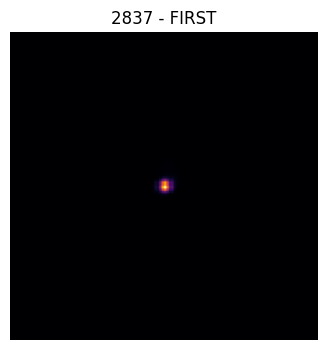

Saved c:\Users\abiga\Desktop\MNRAS_Paper_Code\Source_PNGs\2837\2837_FIRST.png


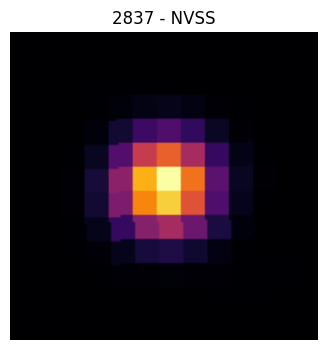

Saved c:\Users\abiga\Desktop\MNRAS_Paper_Code\Source_PNGs\2837\2837_NVSS.png


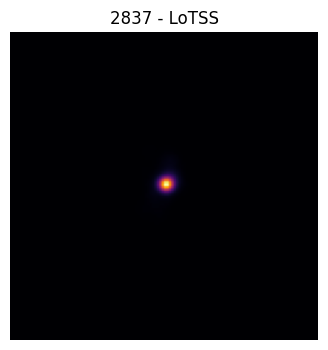

Saved c:\Users\abiga\Desktop\MNRAS_Paper_Code\Source_PNGs\2837\2837_LoTSS.png


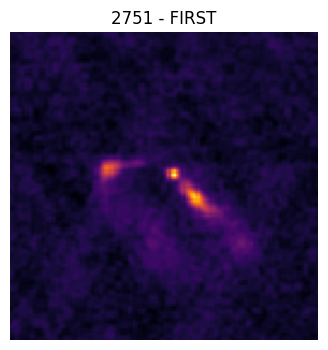

Saved c:\Users\abiga\Desktop\MNRAS_Paper_Code\Source_PNGs\2751\2751_FIRST.png


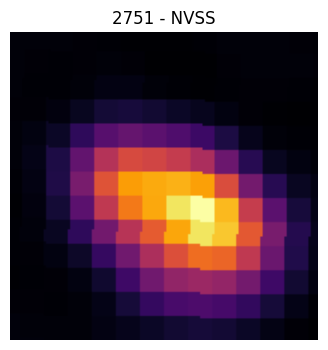

Saved c:\Users\abiga\Desktop\MNRAS_Paper_Code\Source_PNGs\2751\2751_NVSS.png


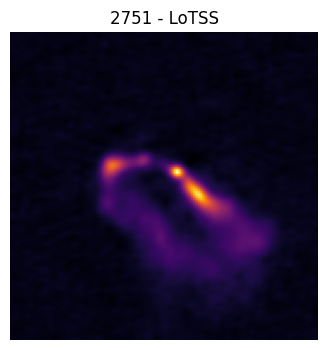

Saved c:\Users\abiga\Desktop\MNRAS_Paper_Code\Source_PNGs\2751\2751_LoTSS.png


In [6]:
# Enter source numbers one after another; leave blank (or type q) to stop.
while True:
    source = input("Source number (blank to stop): ").strip()
    if source.lower() in ("", "q", "quit"):
        break
    save_source(source)